# Notebook 2 — Mechanomyography (MMG) Analysis Pipeline

MMG records the low-frequency mechanical vibrations produced by contracting muscle fibres, typically captured with an accelerometer placed over the muscle belly.

**Why MMG instead of EMG for FES feedback?**  
EMG signals are corrupted by FES electrical artefacts (stimulation pulses appear as large-amplitude spikes that overwhelm the bio-signal). MMG is a *mechanical* measure — it is completely unaffected by the electrical stimulation field (Ibitoye et al. 2014, *Clinical Biomechanics*).

**Features extracted**
| Feature | Sensitivity |
|---------|-------------|
| RMS amplitude | Global muscle activation level; declines with fatigue |
| Mean Power Frequency (MPF) | Downward shift with fatigue — fibre conduction velocity slows |
| Wavelet energy (db4) | Per-band energy — captures both amplitude and frequency changes |

**Reference:** Hamzaid et al. (2017). *MMG and torque during FES-evoked contractions to fatigue in SCI.* Sensors, 17(7):1627.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.signal import welch
import pywt
import pandas as pd

from src.mmg_features import simulate_mmg, extract_mmg_features

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

FS = 1000  # Hz
DURATION = 10.0  # seconds

## 1. Simulate MMG signals — four readiness states

The signal model superposes a dominant oscillation at the state-specific frequency, its harmonics, and Gaussian noise. Signal parameters are based on values reported in Hamzaid et al. (2017) and Ibitoye et al. (2016).

In [2]:
state_labels = [
    ('high_readiness',   'High Readiness',   '#2196F3'),
    ('moderate_readiness', 'Moderate',        '#4CAF50'),
    ('fatigue_overload', 'Fatigue / Overload','#F44336'),
    ('low_engagement',   'Low Engagement',    '#FF9800'),
]

mmg_signals = {}
for state, label, colour in state_labels:
    t, mmg = simulate_mmg(state=state, duration=DURATION, fs=FS)
    mmg_signals[state] = (t, mmg, label, colour)
    print(f'{label:25s} — RMS: {np.sqrt(np.mean(mmg**2)):.3f}')

High Readiness            — RMS: 0.757
Moderate                  — RMS: 0.565
Fatigue / Overload        — RMS: 0.339
Low Engagement            — RMS: 0.153


## 2. Raw MMG signals

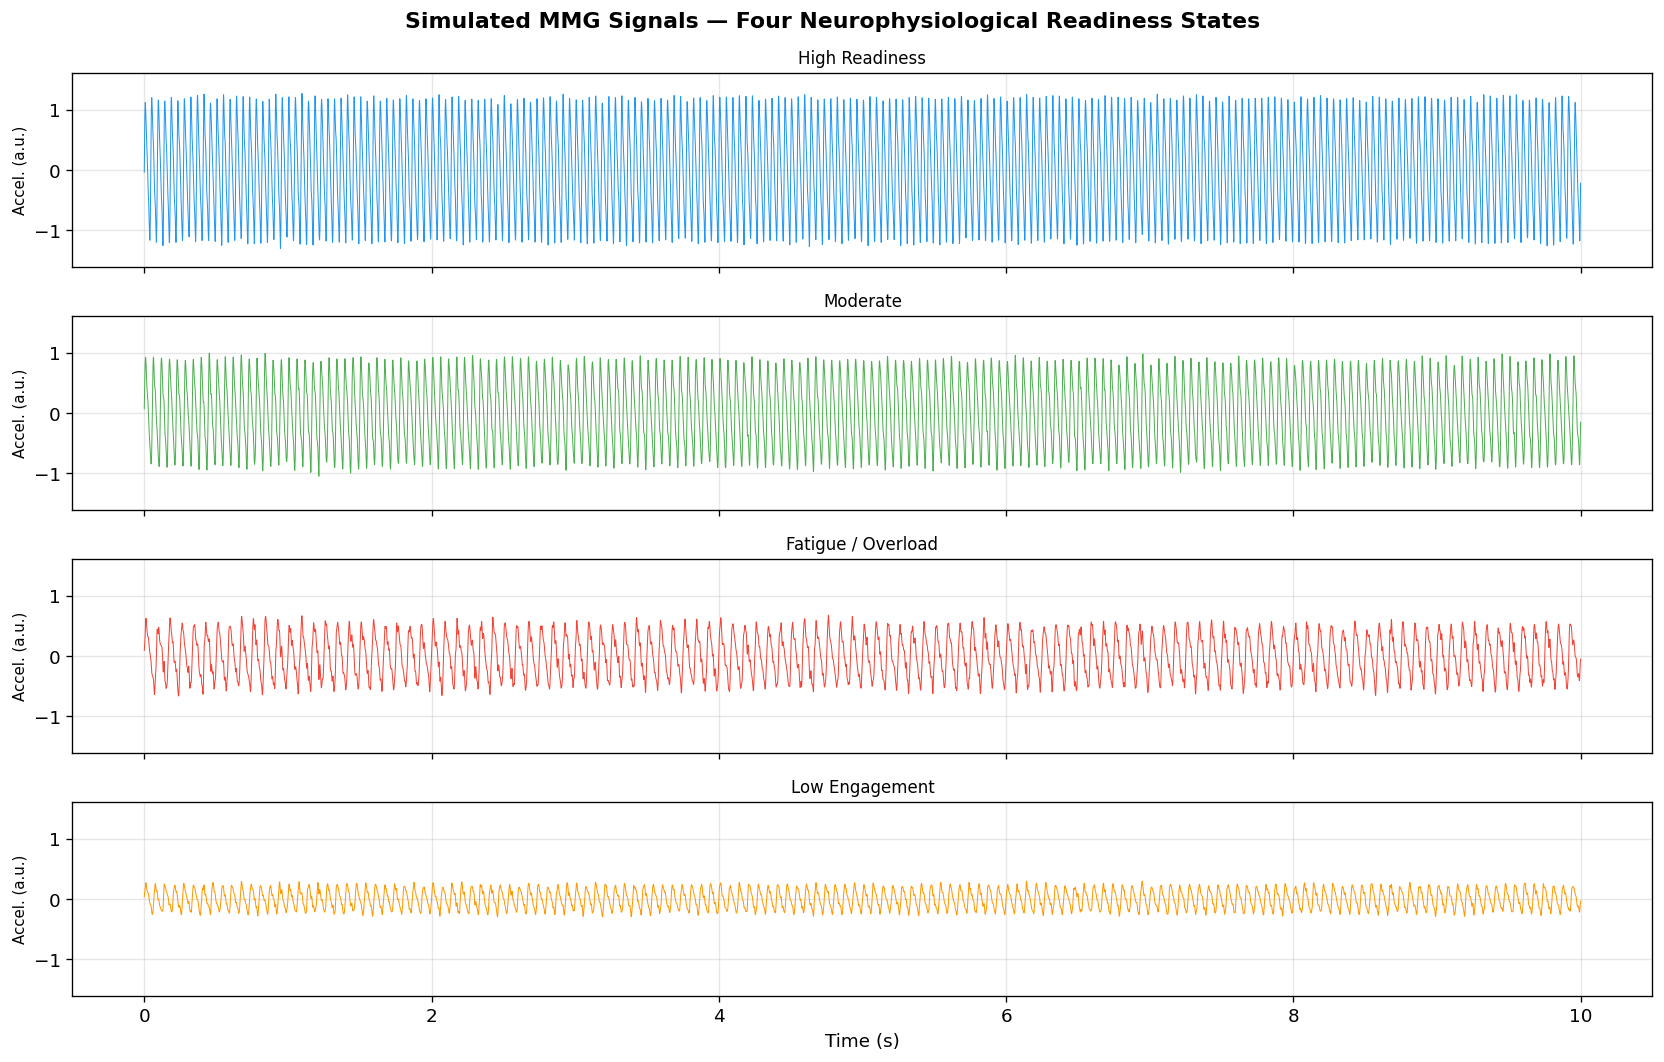

In [3]:
fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)

for ax, (state, (t, mmg, label, colour)) in zip(axes, mmg_signals.items()):
    ax.plot(t, mmg, lw=0.6, color=colour)
    ax.set_ylabel('Accel. (a.u.)', fontsize=9)
    ax.set_title(label, fontsize=10)
    ax.grid(alpha=0.3)
    ax.set_ylim(-1.6, 1.6)

axes[-1].set_xlabel('Time (s)')
fig.suptitle('Simulated MMG Signals — Four Neurophysiological Readiness States', fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Power spectral density

The Mean Power Frequency (MPF) is the first spectral moment. It decreases with muscular fatigue because slow-twitch fibres (recruited later) have lower conduction velocities, shifting power to lower frequencies.

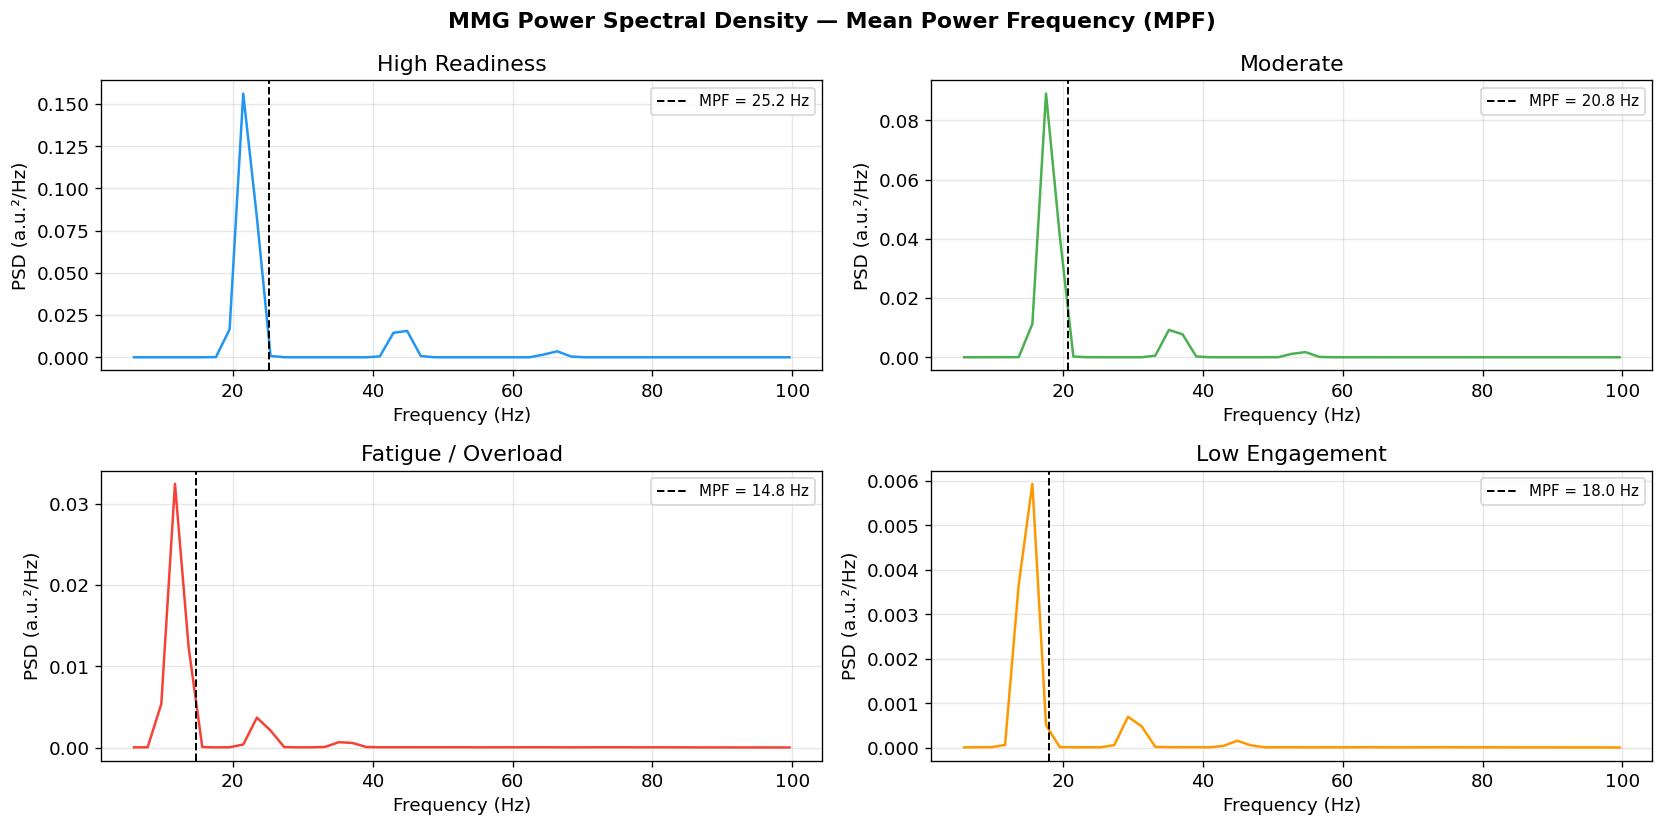

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
axes = axes.flatten()

for ax, (state, (t, mmg, label, colour)) in zip(axes, mmg_signals.items()):
    freqs, psd = welch(mmg, fs=FS, nperseg=512)
    mask = (freqs >= 5) & (freqs <= 100)
    
    mpf = np.trapezoid(freqs[mask] * psd[mask], freqs[mask]) / np.trapezoid(psd[mask], freqs[mask])
    
    ax.plot(freqs[mask], psd[mask], color=colour, lw=1.5)
    ax.axvline(mpf, color='k', ls='--', lw=1.2, label=f'MPF = {mpf:.1f} Hz')
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('PSD (a.u.²/Hz)')
    ax.set_title(label)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

fig.suptitle('MMG Power Spectral Density — Mean Power Frequency (MPF)', fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Wavelet decomposition (db4, 5 levels)

The Daubechies-4 wavelet is well-suited to biomedical transient signals. The wavelet energy in each sub-band captures both amplitude and frequency information in a compact representation.

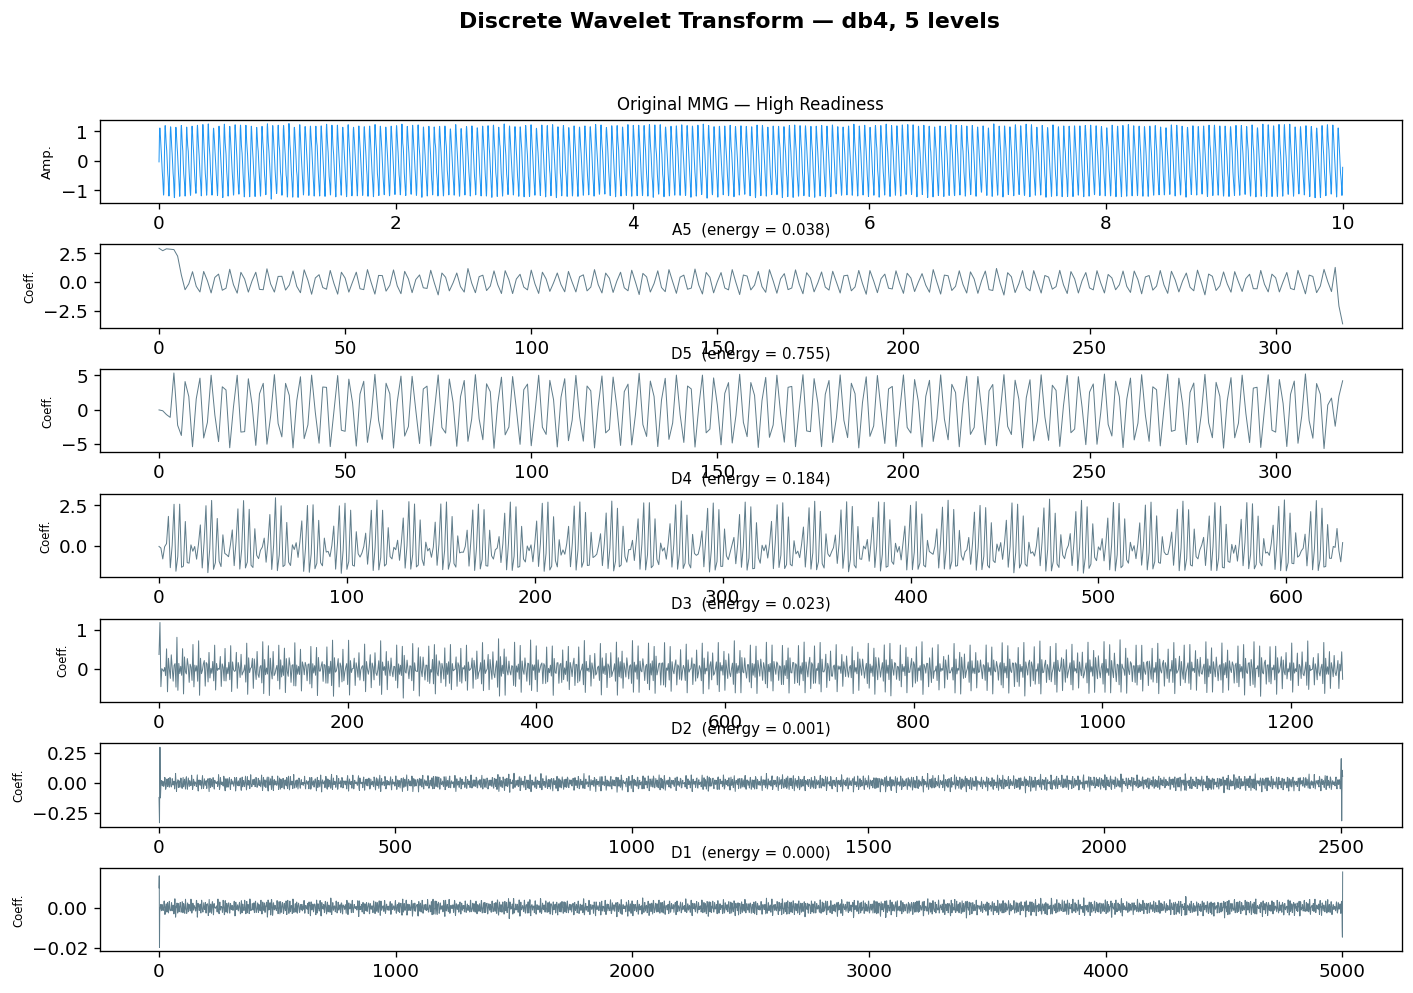

In [5]:
state = 'high_readiness'
t, mmg, label, colour = mmg_signals[state]

wavelet = 'db4'
levels = 5
coeffs = pywt.wavedec(mmg, wavelet=wavelet, level=levels)
coeff_labels = [f'A{levels}'] + [f'D{levels - i}' for i in range(levels)]

fig = plt.figure(figsize=(14, 9))
gs = gridspec.GridSpec(levels + 2, 1, hspace=0.5)

ax0 = fig.add_subplot(gs[0])
ax0.plot(t, mmg, color=colour, lw=0.6)
ax0.set_title(f'Original MMG — {label}', fontsize=10)
ax0.set_ylabel('Amp.', fontsize=8)

for i, (c, clabel) in enumerate(zip(coeffs, coeff_labels)):
    ax = fig.add_subplot(gs[i + 1])
    ax.plot(c, lw=0.6, color='#607D8B')
    energy = np.sum(c ** 2) / sum(np.sum(ci ** 2) for ci in coeffs)
    ax.set_title(f'{clabel}  (energy = {energy:.3f})', fontsize=9)
    ax.set_ylabel('Coeff.', fontsize=7)

fig.suptitle('Discrete Wavelet Transform — db4, 5 levels', fontweight='bold')
plt.show()

## 5. Complete MMG feature extraction — all four states

In [6]:
results = {}
for state, (t, mmg, label, colour) in mmg_signals.items():
    features = extract_mmg_features(mmg, FS)
    results[label] = features

df = pd.DataFrame(results).T
df.index.name = 'State'
df[['RMS_amplitude', 'MPF_Hz', 'WE_D5', 'WE_D4', 'WE_D3', 'WE_A']].round(3)

,RMS_amplitude,MPF_Hz,WE_D5,WE_D4,WE_D3,WE_A
State,,,,,,
High Readiness,0.757,25.235,0.755,0.184,0.023,0.038
Moderate,0.565,20.779,0.645,0.116,0.010,0.228
Fatigue / Overload,0.339,14.757,0.230,0.041,0.010,0.718
Low Engagement,0.153,17.960,0.426,0.077,0.012,0.485


## 6. Feature summary — grouped bar chart

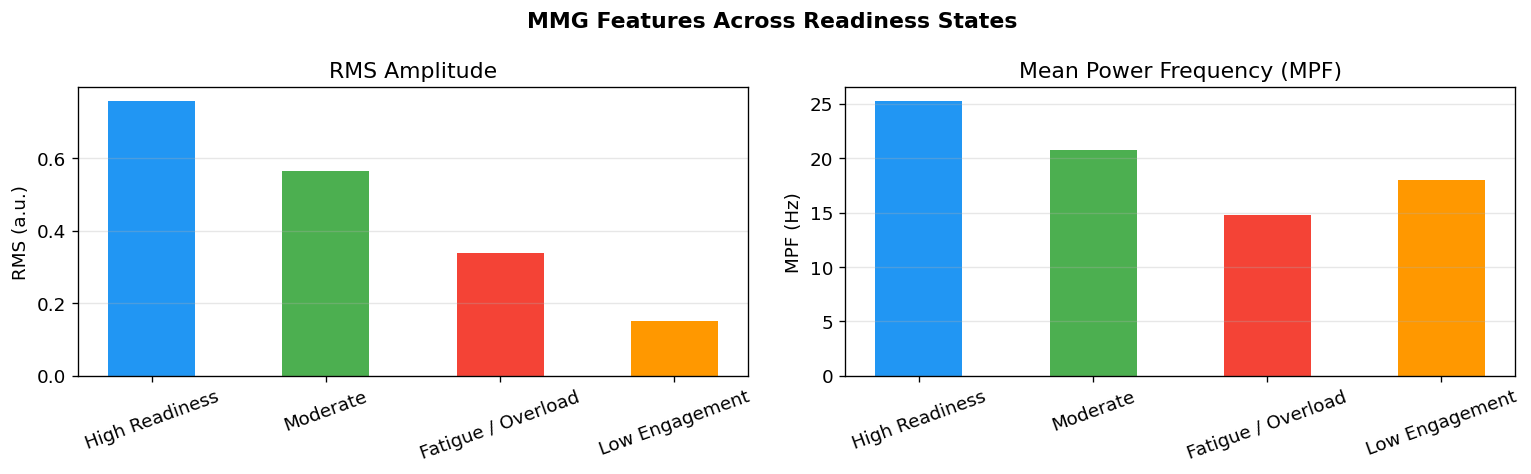

In [7]:
labels_plot = [label for _, label, _ in state_labels]
colours_plot = [colour for _, _, colour in state_labels]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# RMS amplitude
rms_vals = [results[l]['RMS_amplitude'] for l in labels_plot]
axes[0].bar(labels_plot, rms_vals, color=colours_plot, width=0.5)
axes[0].set_title('RMS Amplitude')
axes[0].set_ylabel('RMS (a.u.)')
axes[0].tick_params(axis='x', rotation=20)
axes[0].grid(axis='y', alpha=0.3)

# MPF
mpf_vals = [results[l]['MPF_Hz'] for l in labels_plot]
axes[1].bar(labels_plot, mpf_vals, color=colours_plot, width=0.5)
axes[1].set_title('Mean Power Frequency (MPF)')
axes[1].set_ylabel('MPF (Hz)')
axes[1].tick_params(axis='x', rotation=20)
axes[1].grid(axis='y', alpha=0.3)

fig.suptitle('MMG Features Across Readiness States', fontweight='bold')
plt.tight_layout()
plt.show()

## Summary

- **High readiness** shows the highest RMS amplitude and MPF — fresh muscle fibres, high-frequency oscillations
- **Fatigue/overload** shows the lowest RMS and MPF — slow-twitch fibre recruitment, reduced conduction velocity
- **Low engagement** shows low amplitude *without* a large MPF drop — muscle is not fatigued, simply under-activated
- **Wavelet energy** shifts toward lower-frequency detail bands (D3, D4) under fatigue

These features are linearly separable in the high-readiness vs. fatigue comparison, supporting the feasibility of an SVM or random forest classifier in Phase 2 of the protocol.